# Expt 8: Train a Simple Autoencoder for Dimensionality Reduction and Feature Learning
**Name:** Abhishek J  -  **Roll No.:** 24BAD002  

## Part A: Dataset Preparation and Preprocessing

I0000 00:00:1793529041.052659     467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793529042.817658     467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Abhishek J | Roll No: 24BAD002 | TensorFlow 2.21.0


Training images: (60000, 28, 28) | Testing images: (10000, 28, 28)
Image size: (28, 28) | Pixel range: 0 - 255


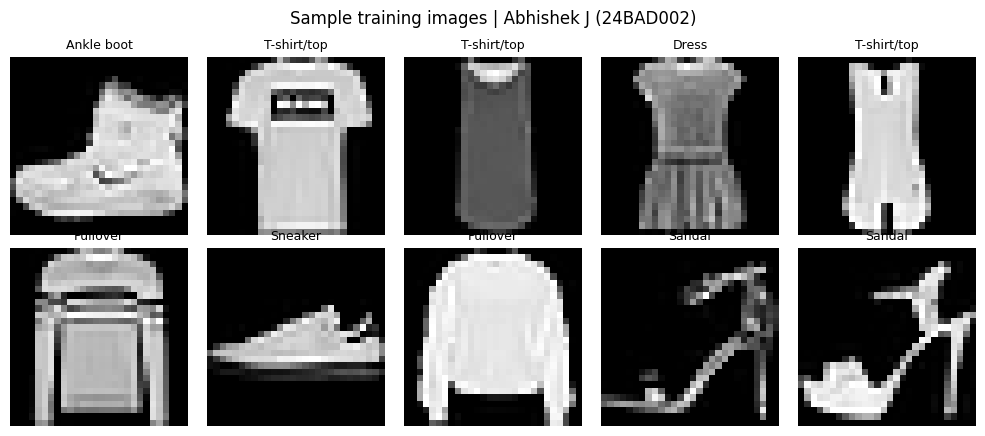

After preprocessing -> train: (60000, 784) test: (10000, 784) | range: 0.0 - 1.0
Input = target (autoencoder reconstructs its own input)


In [ ]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist

ROLL_NO, NAME = "24BAD002", "Abhishek J"
tf.keras.utils.set_random_seed(42)
print(f"{NAME} | Roll No: {ROLL_NO} | TensorFlow {tf.__version__}")

# Load and explore
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("Training images:", x_train.shape, "| Testing images:", x_test.shape)
print("Image size:", x_train.shape[1:], "| Pixel range:", x_train.min(), "-", x_train.max())

# Sample images
fig, ax = plt.subplots(2, 5, figsize=(10, 4.4))
for i, a in enumerate(ax.ravel()):
    a.imshow(x_train[i], cmap="gray"); a.set_title(classes[y_train[i]], fontsize=9); a.axis("off")
fig.suptitle(f"Sample training images | {NAME} ({ROLL_NO})"); plt.tight_layout(); plt.show()

# Normalize to [0, 1] and flatten to 784-d vectors
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
x_train = x_train.reshape(len(x_train), -1)
x_test  = x_test.reshape(len(x_test), -1)
print("After preprocessing -> train:", x_train.shape, "test:", x_test.shape,
      "| range:", x_train.min(), "-", x_train.max())
print("Input = target (autoencoder reconstructs its own input)")

## Part B: Implementing the Encoder and Decoder

In [ ]:
INPUT_DIM, LATENT_DIM = 784, 32

# Encoder: 784 -> 128 -> 32
enc_in = keras.Input(shape=(INPUT_DIM,), name="input_784")
x = layers.Dense(128, activation="relu", name="enc_hidden")(enc_in)
latent = layers.Dense(LATENT_DIM, activation="relu", name="latent_32")(x)
encoder = keras.Model(enc_in, latent, name="encoder")

# Decoder: 32 -> 128 -> 784
dec_in = keras.Input(shape=(LATENT_DIM,), name="latent_input")
x = layers.Dense(128, activation="relu", name="dec_hidden")(dec_in)
dec_out = layers.Dense(INPUT_DIM, activation="sigmoid", name="output_784")(x)
decoder = keras.Model(dec_in, dec_out, name="decoder")

# Autoencoder = decoder(encoder(input))
ae_in = keras.Input(shape=(INPUT_DIM,), name="ae_input")
autoencoder = keras.Model(ae_in, decoder(encoder(ae_in)), name="autoencoder")

print(f"{NAME} | Roll No: {ROLL_NO}")
encoder.summary(); decoder.summary(); autoencoder.summary()

Abhishek J | Roll No: 24BAD002


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_784 (InputLayer)          │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_hidden (Dense)              │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_32 (Dense)               │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Compiling and Training the Autoencoder

Epoch 1/20


235/235 - 5s - 20ms/step - loss: 0.3718 - mse: 0.0447 - val_loss: 0.3151 - val_mse: 0.0239


Epoch 2/20


235/235 - 5s - 20ms/step - loss: 0.3050 - mse: 0.0210 - val_loss: 0.3038 - val_mse: 0.0196


Epoch 3/20


235/235 - 3s - 12ms/step - loss: 0.2962 - mse: 0.0179 - val_loss: 0.2957 - val_mse: 0.0170


... (31 outputs left out)

235/235 - 5s - 21ms/step - loss: 0.2766 - mse: 0.0114 - val_loss: 0.2789 - val_mse: 0.0115


Epoch 20/20


235/235 - 5s - 22ms/step - loss: 0.2763 - mse: 0.0113 - val_loss: 0.2786 - val_mse: 0.0114



Final train loss: 0.2763 | Final val loss: 0.2786


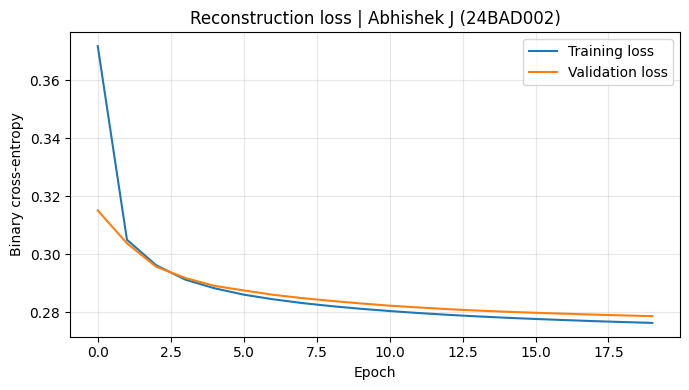

In [ ]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy", metrics=["mse"])

history = autoencoder.fit(x_train, x_train,              # input = target
                          epochs=20, batch_size=256, shuffle=True,
                          validation_data=(x_test, x_test), verbose=2)

h = history.history
print(f"\nFinal train loss: {h['loss'][-1]:.4f} | Final val loss: {h['val_loss'][-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(h["loss"], label="Training loss"); plt.plot(h["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.grid(alpha=.3); plt.legend()
plt.title(f"Reconstruction loss | {NAME} ({ROLL_NO})"); plt.tight_layout(); plt.show()

## Part D: Dimensionality Reduction, Feature Learning and Reconstruction

Abhishek J | Roll No: 24BAD002
Original dimension: 784 -> Latent dimension: 32 (24.5x compression)
Latent array shape: (10000, 32) | Reconstruction shape: (10000, 784)
Test reconstruction MSE: 0.01142


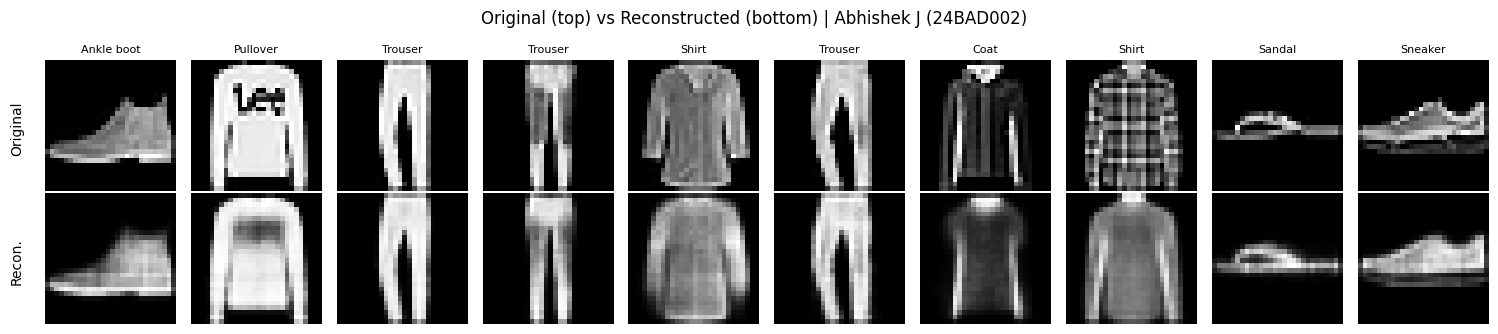

In [ ]:
# Encode test images to latent vectors, then decode to reconstruct
z = encoder.predict(x_test, verbose=0)
recon = decoder.predict(z, verbose=0)
print(f"{NAME} | Roll No: {ROLL_NO}")
print(f"Original dimension: {x_test.shape[1]} -> Latent dimension: {z.shape[1]} "
      f"({x_test.shape[1] / z.shape[1]:.1f}x compression)")
print("Latent array shape:", z.shape, "| Reconstruction shape:", recon.shape)

mse = np.mean((x_test - recon) ** 2)
print(f"Test reconstruction MSE: {mse:.5f}")

# Original vs reconstructed, side by side
n = 10
fig, ax = plt.subplots(2, n, figsize=(15, 3.4))
for i in range(n):
    ax[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray"); ax[0, i].axis("off")
    ax[1, i].imshow(recon[i].reshape(28, 28), cmap="gray"); ax[1, i].axis("off")
    ax[0, i].set_title(classes[y_test[i]], fontsize=8)
ax[0, 0].text(-8, 14, "Original", rotation=90, va="center", fontsize=10)
ax[1, 0].text(-8, 14, "Recon.", rotation=90, va="center", fontsize=10)
fig.suptitle(f"Original (top) vs Reconstructed (bottom) | {NAME} ({ROLL_NO})")
plt.tight_layout(); plt.show()

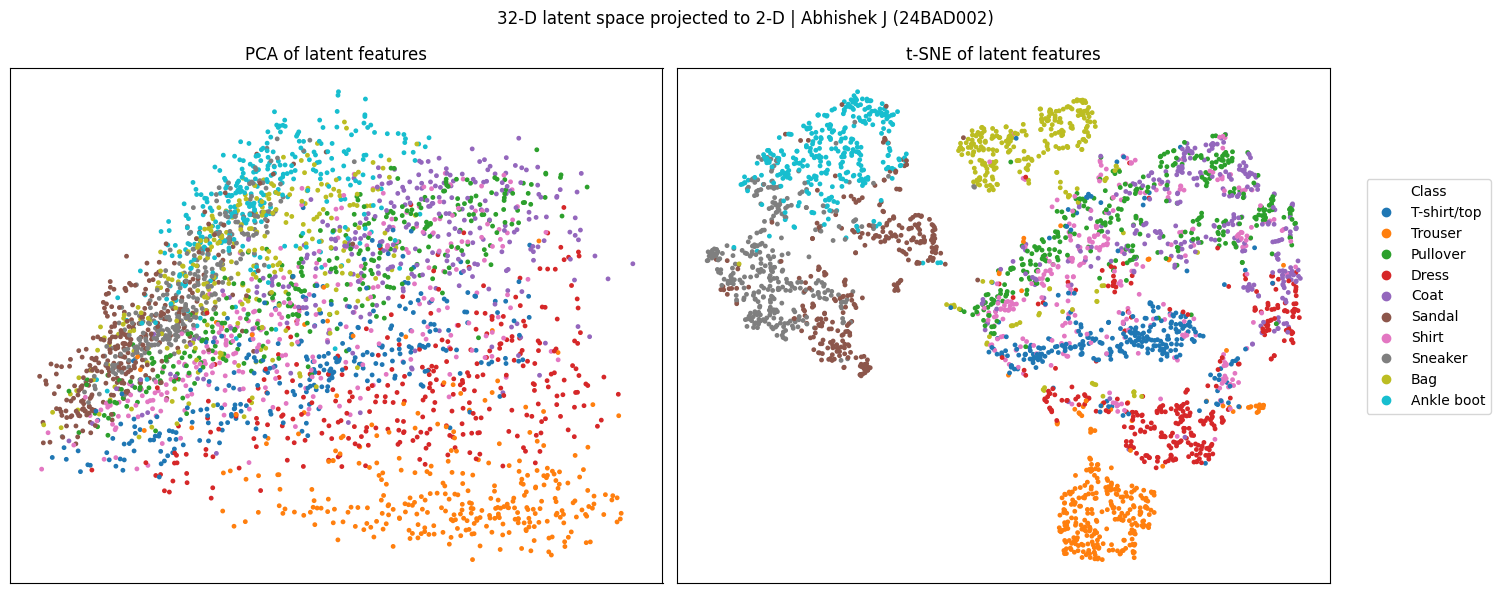

In [ ]:
# Latent-space visualization: PCA and t-SNE (2-D) on 3000 test samples
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

idx = np.random.RandomState(42).choice(len(z), 3000, replace=False)
views = {"PCA of latent features": PCA(n_components=2).fit_transform(z[idx]),
         "t-SNE of latent features": TSNE(n_components=2, random_state=42).fit_transform(z[idx])}

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, (title, e) in zip(ax, views.items()):
    sc = a.scatter(e[:, 0], e[:, 1], c=y_test[idx], cmap="tab10", s=6)
    a.set_title(title); a.set_xticks([]); a.set_yticks([])
fig.legend(sc.legend_elements()[0], classes, loc="center right", title="Class")
fig.suptitle(f"32-D latent space projected to 2-D | {NAME} ({ROLL_NO})")
plt.tight_layout(rect=[0, 0, 0.9, 1]); plt.show()

In [ ]:
# Baseline: linear PCA with the same 32 components
pca = PCA(n_components=LATENT_DIM).fit(x_train)
pca_mse = np.mean((x_test - pca.inverse_transform(pca.transform(x_test))) ** 2)
print(f"Test MSE with 32 dims -> Autoencoder: {mse:.5f} | PCA: {pca_mse:.5f}")

# Save the trained models
autoencoder.save("autoencoder_fashion_mnist.keras")
encoder.save("encoder_fashion_mnist.keras")
decoder.save("decoder_fashion_mnist.keras")
print("Saved: autoencoder / encoder / decoder (.keras)")

Test MSE with 32 dims -> Autoencoder: 0.01142 | PCA: 0.01514
Saved: autoencoder / encoder / decoder (.keras)
